# ATLAS pipeline: IM3 + EIA


set up
1. IM3 base (cleaned **once**, used by every join)
2. EIA generators (Swati)
3. EIA RTO / balancing authority (Swati)
4. EIA retail price + sales (Sajna)
5. EIA state fuel mix (Sajna)
6. Combine into one table
7. Checks
8. Preprocessing
9. column information
10. Validate that every feature is scaled and normalized
11. Compare with the old combined CSV + upload to S3

data - pipeline

In [ ]:
# 0a. Imports + settings
import os, time, shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree
from dotenv import load_dotenv

load_dotenv()
KEY = os.getenv("EIA_API_KEY")
assert KEY, "No EIA key found. Check that .env has EIA_API_KEY=..."

DATA = Path("Data")
OUT = DATA / "pipeline"           
OUT.mkdir(parents=True, exist_ok=True)

IM3_RAW = DATA / "im3_2025_atlas.csv"   
YEAR = 2025              # year for RTO demand/fuel, state fuel mix, and annual retail
RETAIL_MODE = "annual"   # "annual" = YEAR average, or "latest_month" = old behavior
REDOWNLOAD = False       # True = delete cached EIA downloads and pull everything fresh
UPLOAD = True           # True = upload outputs to S3 in section 9 (after checks pass)

ID_DTYPES = {"id": str, "state_id": str, "county_id": str}   # keep leading zeros
N_EXPECTED = 1147
EARTH_KM = 6371.0

# find the raw IM3 CSV if it has a different name
if not IM3_RAW.exists():
    skip = ["clean", "baseline", "multimodal", "combined"]
    cands = [p for p in DATA.glob("im3*.csv") if not any(w in p.name.lower() for w in skip)]
    assert len(cands) == 1, f"Set IM3_RAW to your raw IM3 CSV. Candidates found: {cands}"
    IM3_RAW = cands[0]
print("IM3 raw file:", IM3_RAW)

CACHE_DIRS = [DATA / f"eia_rto_demand_{YEAR}", DATA / f"eia_rto_fuel_{YEAR}", DATA / f"eia_state_gen_{YEAR}"]
if REDOWNLOAD:
    for d in CACHE_DIRS:
        shutil.rmtree(d, ignore_errors=True)
    print("Cleared cached EIA downloads")

IM3 raw file: Data/im3_open_source_data_center_atlas.csv


In [ ]:
#EIA API helpers
RETRY_CODES = {429, 500, 502, 503, 504}


def get_with_retry(url, params, tries=6):
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(url, params=params, timeout=120)
            if r.status_code not in RETRY_CODES:
                r.raise_for_status()          # real errors (bad key, bad facet) stop right away
                return r.json()["response"]
            err = f"HTTP {r.status_code}"
        except (requests.ConnectionError, requests.Timeout) as e:
            err = type(e).__name__
        if attempt == tries:
            raise RuntimeError(f"EIA kept failing ({err}) after {tries} tries. Wait a few minutes and rerun this cell.")
        wait = 10 * attempt
        print(f"   {err}, retrying in {wait}s (try {attempt + 1}/{tries})")
        time.sleep(wait)


def eia_get(route, params):
    """All pages of one EIA query, 5000 rows at a time."""
    url = f"https://api.eia.gov/v2/{route}/data/"
    rows, offset = [], 0
    while True:
        resp = get_with_retry(url, {**params, "api_key": KEY, "offset": offset, "length": 5000})
        rows.extend(resp["data"])
        offset += 5000
        if offset >= int(resp["total"]):
            break
        time.sleep(0.2)
    return pd.DataFrame(rows)


def eia_get_cached(route, params, facet, values, cache_dir, empty_cols):
    """One facet value (one BA, one state...) at a time, each saved to its own CSV.
    If anything fails, rerun the cell: finished ones load from disk."""
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    parts = []
    for i, v in enumerate(values, 1):
        f = cache_dir / f"{v}.csv"
        if f.exists():
            parts.append(pd.read_csv(f, dtype=str))
            continue
        df = eia_get(route, {**params, f"facets[{facet}][]": v})
        if df.empty:   # nothing reported; save an empty file so it isn't re-asked
            df = pd.DataFrame(columns=empty_cols)
        df.to_csv(f, index=False)
        parts.append(df)
        print(f"[{i}/{len(values)}] {v}: {len(df):,} rows")
    return pd.concat(parts, ignore_index=True)


def facet_ids(route, facet):
    url = f"https://api.eia.gov/v2/{route}/facet/{facet}/"
    return [f["id"] for f in get_with_retry(url, {"api_key": KEY})["facets"]]

## 1. IM3 base (cleaned once)
Same filters every join used before → 1147 facilities. IDs stay strings so leading zeros are never lost (that was why the retail file needed `zfill(10)`).
Blank state/county fields (the 2 San Francisco sites) are filled from the Census county map, so no join has to patch them later.

In [3]:
# 1a. Load and clean
base = pd.read_csv(IM3_RAW, dtype=ID_DTYPES)
print("raw:", base.shape)

base = base.drop_duplicates()
base = base.drop_duplicates(subset=["id"]).reset_index(drop=True)
base = base[base["sqft"] > 0]          # drops the 'point' rows (no sqft)
base = base[base["lat"].between(17.0, 72.0) & base["lon"].between(-170.0, -65.0)].reset_index(drop=True)

assert base["id"].is_unique
print(len(base), f"facilities (expect {N_EXPECTED})")
print(base["type"].value_counts().to_dict())

raw: (1242, 13)
1147 facilities (expect 1147)
{'building': 1039, 'campus': 108}


In [ ]:
# 1b. Census county map (used here, in the RTO join, and in the checks).
county_zip = DATA / "cb_2023_us_county_500k.zip"
if not county_zip.exists():
    r = requests.get("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip", timeout=180)
    r.raise_for_status()
    county_zip.write_bytes(r.content)
counties = (gpd.read_file(county_zip)
              [["GEOID", "STATEFP", "COUNTYFP", "STUSPS", "STATE_NAME", "NAMELSAD", "geometry"]]
              .to_crs("EPSG:4326"))

# which county each facility sits in
pts = gpd.GeoDataFrame(base[["id"]], geometry=gpd.points_from_xy(base["lon"], base["lat"]), crs="EPSG:4326")
loc = (gpd.sjoin(pts, counties, how="left", predicate="within")
          .drop_duplicates("id").set_index("id"))

# fill blank location fields from the map (only blanks are touched)
for col, src in [("state_abb", "STUSPS"), ("state", "STATE_NAME"), ("state_id", "STATEFP"),
                 ("county_id", "COUNTYFP"), ("county", "NAMELSAD")]:
    if col not in base.columns:
        continue
    blank = base[col].isna() | (base[col].astype(str).str.strip() == "")
    if blank.any():
        print(f"Filling {blank.sum()} blank '{col}' from the county map, ids:", base.loc[blank, "id"].tolist())
        base.loc[blank, col] = base.loc[blank, "id"].map(loc[src])

assert base["state_abb"].notna().all(), "some facilities still have no state"

In [5]:
# 1c. Derived columns + save the baseline
base["county_fips"] = base["state_id"].str.zfill(2) + base["county_id"].str.zfill(3)

# size_class: 0 = small (<20k sqft), 1 = medium (20k-100k), 2 = large/hyperscale (100k+)
base["size_class"] = pd.cut(base["sqft"], bins=[0, 20_000, 100_000, np.inf],
                            labels=[0, 1, 2], right=False).astype(int)

assert len(base) == N_EXPECTED, f"expected {N_EXPECTED} facilities, got {len(base)}"
base.to_csv(OUT / "im3_baseline.csv", index=False)
print("Saved", OUT / "im3_baseline.csv", base.shape)
base.head()

Saved Data/pipeline/im3_baseline.csv (1147, 15)


,id,state,state_abb,state_id,county,county_id,operator,ref,name,sqft,lon,lat,type,county_fips,size_class
0,0002744301,New Jersey,NJ,34,Middlesex County,023,NaN,NaN,Verizon,105786.0,-74.496521,40.544256,building,34023,2
1,0007805491,Ohio,OH,39,Franklin County,049,NaN,NaN,Discover Financial Services New Albany,188209.0,-82.814358,40.100657,building,39049,2
2,0009474864,North Carolina,NC,37,Caldwell County,027,Google,NaN,Google Data Center,3407194.0,-81.546515,35.894738,campus,37027,2
3,0013924557,Iowa,IA,19,Polk County,153,Microsoft,NaN,Project Alluvion,10962475.0,-93.711719,41.515955,campus,19153,2
4,0014593270,North Carolina,NC,37,Catawba County,035,NaN,NaN,Apple - Maiden Data Center,5431080.0,-81.261809,35.588771,campus,37035,2


### Optional EDA (from Sajna's preprocessing notebook)
Plots only; skip if you don't need them. Nothing below depends on these.

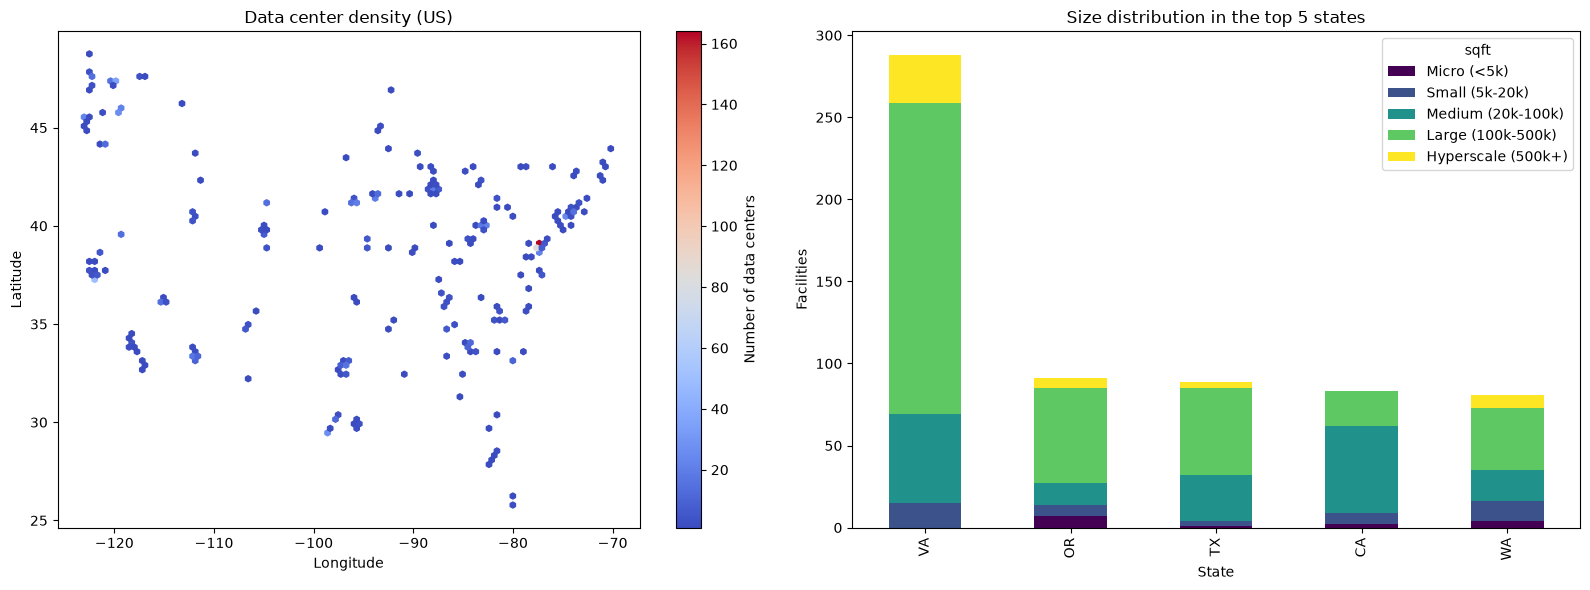

In [6]:
# EDA: where the data centers are, and their sizes in the top 5 states
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hb = axes[0].hexbin(base["lon"], base["lat"], gridsize=(100, 50), cmap="coolwarm", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="Number of data centers")
axes[0].set(title="Data center density (US)", xlabel="Longitude", ylabel="Latitude")

size_labels = ["Micro (<5k)", "Small (5k-20k)", "Medium (20k-100k)", "Large (100k-500k)", "Hyperscale (500k+)"]
size_cat = pd.cut(base["sqft"], bins=[0, 5_000, 20_000, 100_000, 500_000, np.inf], labels=size_labels, right=False)
top5 = base["state_abb"].value_counts().head(5).index
tab = pd.crosstab(base.loc[base["state_abb"].isin(top5), "state_abb"], size_cat[base["state_abb"].isin(top5)])
tab.loc[tab.sum(axis=1).sort_values(ascending=False).index].plot(kind="bar", stacked=True, colormap="viridis", ax=axes[1])
axes[1].set(title="Size distribution in the top 5 states", xlabel="State", ylabel="Facilities")
plt.tight_layout()
plt.show()

## 2. EIA generators (Swati)
Route `electricity/operating-generator-capacity`, latest month. Features: distance to nearest plant, plants / capacity / renewable capacity within 50 km, distance to nearest plant ≥ 100 MW.

In [7]:
# 2a. Download operating generators for the latest month
GEN_ROUTE = "electricity/operating-generator-capacity"
latest = get_with_retry(f"https://api.eia.gov/v2/{GEN_ROUTE}", {"api_key": KEY})["endPeriod"]
print("latest month:", latest)

gen_raw = eia_get(GEN_ROUTE, {
    "frequency": "monthly",
    "data[0]": "nameplate-capacity-mw",
    "data[1]": "latitude",
    "data[2]": "longitude",
    "facets[status][]": "OP",
    "start": latest,
    "end": latest,
})
gen_raw.to_csv(DATA / f"eia_generators_{latest}_raw.csv", index=False)
print(f"{len(gen_raw):,} generators")

latest month: 2026-07
26,072 generators


In [8]:
# 2b. One row per plant
gen = gen_raw.copy()
for c in ["nameplate-capacity-mw", "latitude", "longitude"]:
    gen[c] = pd.to_numeric(gen[c], errors="coerce")
gen = gen.dropna(subset=["latitude", "longitude", "nameplate-capacity-mw"])

RENEWABLE_GEN_CODES = ["SUN", "WND", "WAT", "GEO"]
gen["renewable_mw"] = gen["nameplate-capacity-mw"].where(gen["energy_source_code"].isin(RENEWABLE_GEN_CODES), 0)

plants = gen.groupby("plantid").agg(
    plant_name=("plantName", "first"),
    lat=("latitude", "first"),
    lon=("longitude", "first"),
    capacity_mw=("nameplate-capacity-mw", "sum"),
    renewable_mw=("renewable_mw", "sum"),
).reset_index()
print(f"{len(plants):,} plants")

14,147 plants


In [9]:
# 2c. Distance and 50 km features (EPSG:5070 = equal-area meters for the lower 48)
fac = gpd.GeoDataFrame(base[["id"]], geometry=gpd.points_from_xy(base["lon"], base["lat"]),
                       crs="EPSG:4326").to_crs("EPSG:5070")
plants_gdf = gpd.GeoDataFrame(plants, geometry=gpd.points_from_xy(plants["lon"], plants["lat"]),
                              crs="EPSG:4326").to_crs("EPSG:5070")

near = gpd.sjoin_nearest(fac, plants_gdf[["plantid", "geometry"]], distance_col="dist_m").drop_duplicates("id")
near["nearest_plant_km"] = near["dist_m"] / 1000

circles = fac.copy()
circles["geometry"] = circles.buffer(50_000)
inside = gpd.sjoin(circles, plants_gdf[["capacity_mw", "renewable_mw", "geometry"]], predicate="contains", how="left")
within = inside.groupby("id").agg(
    plants_50km=("capacity_mw", "count"),
    capacity_50km_mw=("capacity_mw", "sum"),
    renewable_50km_mw=("renewable_mw", "sum"),
).reset_index()
within["renewable_share_50km"] = within["renewable_50km_mw"] / within["capacity_50km_mw"]   # NaN when no plants

big = plants_gdf[plants_gdf["capacity_mw"] >= 100]
near_big = gpd.sjoin_nearest(fac, big[["geometry"]], distance_col="dist_m").drop_duplicates("id")
near_big["nearest_big_plant_km"] = near_big["dist_m"] / 1000

gen_features = (base[["id"]]
                .merge(near[["id", "nearest_plant_km"]], on="id", how="left", validate="one_to_one")
                .merge(within, on="id", how="left", validate="one_to_one")
                .merge(near_big[["id", "nearest_big_plant_km"]], on="id", how="left", validate="one_to_one"))

assert len(gen_features) == N_EXPECTED and gen_features["id"].is_unique
gen_features.to_csv(OUT / "eia_generator_features.csv", index=False)
print("Saved", OUT / "eia_generator_features.csv", gen_features.shape)
gen_features.describe().T

Saved Data/pipeline/eia_generator_features.csv (1147, 7)


,count,mean,std,min,25%,50%,75%,max
nearest_plant_km,1147.0,7.094129,6.114102,0.009526,2.121821,5.482270,9.720620,34.669662
plants_50km,1147.0,51.491718,52.266740,2.000000,16.000000,36.000000,69.000000,296.000000
capacity_50km_mw,1147.0,3900.859459,3629.450776,12.900000,1768.400000,3121.000000,4352.900000,20826.700000
renewable_50km_mw,1147.0,629.614211,1021.447648,0.000000,121.000000,227.200000,543.100000,7070.800000
renewable_share_50km,1147.0,0.216906,0.281761,0.000000,0.036863,0.104556,0.239723,1.000000
nearest_big_plant_km,1147.0,15.701929,12.585866,0.099693,7.318094,12.251464,21.470669,85.332004


## 3. EIA RTO / balancing authority (Swati)
Each facility gets a BA by voting among its nearest plants (same county → same state → any), with the generation-only BA filter and the WA/OR county overrides. Then hourly demand and daily fuel mix for that BA.

In [10]:
# 3a. Plants with a valid RTO BA code (uses gen_raw from section 2)
ba_cols = [c for c in gen_raw.columns if "balancing" in c.lower() and "code" in c.lower()]
assert ba_cols, f"No balancing authority code column. Columns are: {list(gen_raw.columns)}"
BA_COL = ba_cols[0]

rto_codes = set(facet_ids("electricity/rto/region-data", "respondent"))

ba_plants = gen_raw[["plantid", "latitude", "longitude", BA_COL]].copy()
ba_plants["latitude"] = pd.to_numeric(ba_plants["latitude"], errors="coerce")
ba_plants["longitude"] = pd.to_numeric(ba_plants["longitude"], errors="coerce")
ba_plants["ba"] = ba_plants[BA_COL].astype(str).str.strip().str.upper()
ba_plants = ba_plants.dropna(subset=["latitude", "longitude"])

dropped = ba_plants.loc[~ba_plants["ba"].isin(rto_codes), "ba"].value_counts()
print("Plant BA codes not in RTO data (dropped):", dropped.to_dict())
ba_plants = ba_plants[ba_plants["ba"].isin(rto_codes)]

ba_plants = (ba_plants.groupby("plantid", as_index=False)     # one row per plant
                      .agg(latitude=("latitude", "first"),
                           longitude=("longitude", "first"),
                           ba=("ba", "first")))
print(f"{len(ba_plants):,} plants with a valid BA code")

Plant BA codes not in RTO data (dropped): {'NA': 40, 'HECO': 34, 'NBSO': 14, 'GRIS': 2, 'CEA': 1}
13,922 plants with a valid BA code


In [ ]:

GEN_ONLY_BAS = {"AVRN", "DEAA", "EEI", "GRID", "GRIF", "GWA", "HGMA", "SEPA", "WWA", "YAD"}

# county FIPS -> BA of the utility that actually serves the county (EIA-861 utility territories)
COUNTY_OVERRIDES = {
    "53025": ("GCPD", "Grant County WA: Grant County PUD (Quincy)"),
    "53017": ("DOPD", "Douglas County WA: Douglas County PUD (East Wenatchee)"),
    "41059": ("BPAT", "Umatilla County OR: Umatilla Electric Co-op / City of Hermiston, BPA customers"),
    "41065": ("BPAT", "Wasco County OR: Northern Wasco County PUD (The Dalles), BPA customer"),
}
for fips, (ba, why) in COUNTY_OVERRIDES.items():
    assert ba in rto_codes, f"{ba} is not an RTO respondent; remove the {fips} override"

K = 5            
K_SEARCH = 300    
MAX_KM = 100     

# county + state FIPS for every plant (counties loaded in 1b)
ppts = gpd.GeoDataFrame(ba_plants[["plantid"]],
                        geometry=gpd.points_from_xy(ba_plants["longitude"], ba_plants["latitude"]),
                        crs="EPSG:4326")
ppts = gpd.sjoin(ppts, counties[["GEOID", "STATEFP", "geometry"]], how="left", predicate="within").drop_duplicates("plantid")
ba_plants = ba_plants.merge(ppts[["plantid", "GEOID", "STATEFP"]]
                              .rename(columns={"GEOID": "p_fips", "STATEFP": "p_state"}),
                            on="plantid", how="left")
print(f"{ba_plants['p_fips'].notna().mean():.1%} of plants placed in a county")

n_before = len(ba_plants)
ba_plants = ba_plants[~ba_plants["ba"].isin(GEN_ONLY_BAS)].reset_index(drop=True)
print(n_before - len(ba_plants), "plants dropped because their BA is generation-only")

tree = BallTree(np.radians(ba_plants[["latitude", "longitude"]].values), metric="haversine")
dist, idx = tree.query(np.radians(base[["lat", "lon"]].astype(float).values),
                       k=min(K_SEARCH, len(ba_plants)))   # sorted closest first

p_ba = ba_plants["ba"].values
p_st = ba_plants["p_state"].fillna("").values
p_co = ba_plants["p_fips"].fillna("").values
f_st = base["state_id"].str.zfill(2).values
f_co = base["county_fips"].values

ba_codes, shares, levels = [], [], []
for i in range(len(base)):
    cand = idx[i]
    same_county = cand[p_co[cand] == f_co[i]][:K]
    same_state = cand[p_st[cand] == f_st[i]][:K]
    if len(same_county):
        pick, level = same_county, "county"
    elif len(same_state):
        pick, level = same_state, "state"
    else:
        pick, level = cand[:K], "nearest"
    ba, n = Counter(p_ba[pick]).most_common(1)[0]   # ties go to the closer plant
    ba_codes.append(ba)
    shares.append(n / len(pick))
    levels.append(level)

rto = base[["id", "state_abb", "county", "county_fips"]].copy()
rto["ba_code"] = ba_codes
rto["vote_share"] = shares
rto["matched_by"] = levels
rto["ba_plant_km"] = dist[:, 0] * EARTH_KM

for fips, (ba, why) in COUNTY_OVERRIDES.items():
    hit = rto["county_fips"] == fips
    if hit.any():
        print(f"Override: {hit.sum():>3} facilities -> {ba}  ({why})")
    rto.loc[hit, "ba_code"] = ba
    rto.loc[hit, "matched_by"] = "override"

too_far = rto["ba_plant_km"] > MAX_KM
rto.loc[too_far, "ba_code"] = np.nan
print("How each facility was matched:", rto["matched_by"].value_counts().to_dict())
print(too_far.sum(), "facilities farther than", MAX_KM, "km from any plant (BA left blank)")


top_states = rto["state_abb"].value_counts().head(10).index
print(pd.crosstab(rto.loc[rto["state_abb"].isin(top_states), "state_abb"],
                  rto.loc[rto["state_abb"].isin(top_states), "ba_code"])
        .apply(lambda r: r[r > 0].sort_values(ascending=False).to_dict(), axis=1)
        .to_string())

99.9% of plants placed in a county
39 plants dropped because their BA is generation-only
Override:  38 facilities -> GCPD  (Grant County WA: Grant County PUD (Quincy))
Override:  13 facilities -> DOPD  (Douglas County WA: Douglas County PUD (East Wenatchee))
Override:  25 facilities -> BPAT  (Umatilla County OR: Umatilla Electric Co-op / City of Hermiston, BPA customers)
Override:   2 facilities -> BPAT  (Wasco County OR: Northern Wasco County PUD (The Dalles), BPA customer)
How each facility was matched: {'county': 1051, 'override': 78, 'state': 18}
0 facilities farther than 100 km from any plant (BA left blank)
state_abb
AZ                              {'AZPS': 20, 'SRP': 20}
CA                   {'CISO': 72, 'BANC': 6, 'LDWP': 5}
IA                                         {'MISO': 56}
IL                               {'PJM': 35, 'MISO': 1}
NJ                                          {'PJM': 45}
OH                                          {'PJM': 55}
OR                  {'BPAT': 50, 

In [12]:
# 3c. Hourly demand for one year, one BA at a time (cached per BA)
bas = sorted(rto["ba_code"].dropna().unique())
print(len(bas), "BAs:", bas)

demand = eia_get_cached("electricity/rto/region-data", {
    "frequency": "hourly",
    "data[]": "value",
    "facets[type][]": "D",                 # D = demand
    "start": f"{YEAR}-01-01T00",
    "end": f"{YEAR}-12-31T23",
    "sort[0][column]": "period", "sort[0][direction]": "asc",
}, "respondent", bas, DATA / f"eia_rto_demand_{YEAR}", ["period", "respondent", "value"])
print(f"{len(demand):,} hourly rows")

39 BAs: ['AVA', 'AZPS', 'BANC', 'BPAT', 'CHPD', 'CISO', 'CPLE', 'DOPD', 'DUK', 'EPE', 'ERCO', 'FMPP', 'FPC', 'FPL', 'GCPD', 'GVL', 'ISNE', 'JEA', 'LDWP', 'LGEE', 'MISO', 'NEVP', 'NWMT', 'NYIS', 'PACE', 'PACW', 'PGE', 'PJM', 'PNM', 'PSCO', 'PSEI', 'SC', 'SCEG', 'SOCO', 'SRP', 'SWPP', 'TEC', 'TVA', 'WACM']
341,613 hourly rows


In [13]:
# 3d. Demand features per BA
d = demand[["period", "respondent", "value"]].copy()
d["value"] = pd.to_numeric(d["value"], errors="coerce")
d = d.drop_duplicates(subset=["period", "respondent"])
d = d[d["value"] > 0]                                   # drops missing hours and bad negative readings

# EIA-930 hourly data has glitch spikes; drop readings over 4x the BA's median
spikes = d["value"] > 4 * d.groupby("respondent")["value"].transform("median")
print(spikes.sum(), "spike readings dropped")
d = d[~spikes]

HOURS = 8784 if pd.Timestamp(f"{YEAR}-12-31").is_leap_year else 8760
ba_demand = (d.groupby("respondent")["value"]
              .agg(ba_peak_mw="max", ba_avg_mw="mean", hours="count")
              .reset_index()
              .rename(columns={"respondent": "ba_code"}))
ba_demand["ba_peak_to_avg"] = ba_demand["ba_peak_mw"] / ba_demand["ba_avg_mw"]
ba_demand["ba_demand_coverage"] = ba_demand["hours"] / HOURS
ba_demand = ba_demand.drop(columns="hours")

print("BAs with under 90% of hours reported:")
print(ba_demand.loc[ba_demand["ba_demand_coverage"] < 0.9, ["ba_code", "ba_demand_coverage"]])
print("BAs with no demand data (get NaN):", sorted(set(bas) - set(ba_demand["ba_code"])))

0 spike readings dropped
BAs with under 90% of hours reported:
Empty DataFrame
Columns: [ba_code, ba_demand_coverage]
Index: []
BAs with no demand data (get NaN): []


In [14]:
# 3e. Daily generation by fuel type (one timezone only, or rows get duplicated)
tzs = facet_ids("electricity/rto/daily-fuel-type-data", "timezone")
TZ = "Central" if "Central" in tzs else tzs[0]
print("Valid timezones:", tzs, "-> using", TZ)

fuel = eia_get_cached("electricity/rto/daily-fuel-type-data", {
    "frequency": "daily",
    "data[]": "value",
    "facets[timezone][]": TZ,
    "start": f"{YEAR}-01-01",
    "end": f"{YEAR}-12-31",
    "sort[0][column]": "period", "sort[0][direction]": "asc",
}, "respondent", bas, DATA / f"eia_rto_fuel_{YEAR}", ["period", "respondent", "fueltype", "value"])
print(f"{len(fuel):,} daily rows")

Valid timezones: ['Pacific', 'Eastern', 'Mountain', 'Central', 'Arizona'] -> using Central
88,038 daily rows


In [15]:
# 3f. Fuel-mix shares per BA
fl = fuel.reindex(columns=["period", "respondent", "fueltype", "value"]).dropna(subset=["respondent", "fueltype"]).copy()
fl["value"] = pd.to_numeric(fl["value"], errors="coerce")
fl = fl.drop_duplicates(subset=["period", "respondent", "fueltype"])
fl = fl[fl["value"] > 0]      # negatives are storage charging / net consumption, not generation
print("Fuel codes present:", sorted(fl["fueltype"].unique()))

ba_annual = fl.pivot_table(index="respondent", columns="fueltype", values="value", aggfunc="sum", fill_value=0)
STORAGE = ["BAT", "PS", "OES", "UES"]   # storage re-releases power made earlier; not a fuel source
ba_annual = ba_annual.drop(columns=[c for c in STORAGE if c in ba_annual.columns])
ba_total = ba_annual.sum(axis=1)

def ba_share(codes):
    return ba_annual[[c for c in codes if c in ba_annual.columns]].sum(axis=1) / ba_total

BA_SOLAR = ["SUN", "SNB"]          # SNB = solar with attached battery
BA_WIND = ["WND", "WNB"]           # WNB = wind with attached battery
BA_FOSSIL = ["COL", "NG", "OIL"]
BA_RENEWABLE = BA_SOLAR + BA_WIND + ["WAT", "GEO"]   # same definition as the generator join (no nuclear)

ba_fuel = pd.DataFrame({
    "ba_share_coal":      ba_share(["COL"]),
    "ba_share_gas":       ba_share(["NG"]),
    "ba_share_nuclear":   ba_share(["NUC"]),
    "ba_share_hydro":     ba_share(["WAT"]),
    "ba_share_solar":     ba_share(BA_SOLAR),
    "ba_share_wind":      ba_share(BA_WIND),
    "ba_share_fossil":    ba_share(BA_FOSSIL),
    "ba_share_renewable": ba_share(BA_RENEWABLE),
    "ba_share_clean":     ba_share(BA_RENEWABLE + ["NUC"]),   # renewable + nuclear
    "ba_total_gen_mwh":   ba_total,
}).reset_index().rename(columns={"respondent": "ba_code"})

assert (ba_fuel.filter(like="ba_share").fillna(0) <= 1.0001).all().all()

Fuel codes present: ['BAT', 'COL', 'GEO', 'NG', 'NUC', 'OES', 'OIL', 'OTH', 'PS', 'SNB', 'SUN', 'WAT', 'WND']


In [16]:
# 3g. RTO features, one row per facility
rto_features = (rto[["id", "ba_code"]]
                .merge(ba_demand, on="ba_code", how="left", validate="many_to_one")
                .merge(ba_fuel, on="ba_code", how="left", validate="many_to_one"))

assert len(rto_features) == N_EXPECTED and rto_features["id"].is_unique
rto_features.to_csv(OUT / "eia_rto_features.csv", index=False)
print("Saved", OUT / "eia_rto_features.csv", rto_features.shape)
print(rto_features.isna().mean().round(3).sort_values(ascending=False).head())

Saved Data/pipeline/eia_rto_features.csv (1147, 16)
id                0.0
ba_code           0.0
ba_peak_mw        0.0
ba_avg_mw         0.0
ba_peak_to_avg    0.0
dtype: float64


## 4. EIA retail price + sales (Sajna)
Route `electricity/retail-sales`, commercial sector, joined by state from the **base** table (fixes the Hamilton County OH / San Francisco issues at the source).
EIA reports sales in million kWh = **GWh**, so the column is `comm_elec_sales_gwh`. The old `est_*` power/cost columns are dropped.

In [17]:
# 4a. Download
states = sorted(base["state_abb"].dropna().unique())
freq = "annual" if RETAIL_MODE == "annual" else "monthly"

retail_params = {
    "frequency": freq,
    "data[0]": "price",
    "data[1]": "sales",
    "facets[sectorid][]": "COM",
    "sort[0][column]": "period", "sort[0][direction]": "desc",
}
if RETAIL_MODE == "annual":
    retail_params.update({"start": str(YEAR), "end": str(YEAR)})

retail_raw = eia_get("electricity/retail-sales", retail_params)
retail_raw.to_csv(DATA / f"eia_retail_sales_{freq}.csv", index=False)
print(f"{len(retail_raw):,} rows")
for c in ["price-units", "sales-units"]:
    if c in retail_raw.columns:
        print(c, retail_raw[c].dropna().unique())

62 rows
price-units <StringArray>
['cents per kilowatt-hour']
Length: 1, dtype: str
sales-units <StringArray>
['million kilowatt hours']
Length: 1, dtype: str


In [18]:
# 4b. One row per state, then join to facilities
ret = retail_raw[["period", "stateid", "price", "sales"]].rename(columns={
    "period": "retail_period",
    "stateid": "state_abb",
    "price": "comm_elec_price_cents_kwh",
    "sales": "comm_elec_sales_gwh",      # million kWh = GWh
})
ret = ret[ret["state_abb"].isin(states)].copy()     # drops US / regional totals
for c in ["comm_elec_price_cents_kwh", "comm_elec_sales_gwh"]:
    ret[c] = pd.to_numeric(ret[c], errors="coerce")

if RETAIL_MODE == "latest_month":
    ret = ret[ret["retail_period"] == ret["retail_period"].max()]

assert ret["state_abb"].is_unique, "more than one retail row per state"
print("Retail period(s):", ret["retail_period"].unique())
print("States with no retail data:", sorted(set(states) - set(ret["state_abb"])) or "none")

retail_features = (base[["id", "state_abb"]]
                   .merge(ret, on="state_abb", how="left", validate="many_to_one")
                   .drop(columns="state_abb"))

assert len(retail_features) == N_EXPECTED and retail_features["id"].is_unique
retail_features.to_csv(OUT / "eia_retail_features.csv", index=False)
print("Saved", OUT / "eia_retail_features.csv", retail_features.shape)
print(retail_features["comm_elec_price_cents_kwh"].isna().sum(), "facilities missing a price")

Retail period(s): <StringArray>
['2025']
Length: 1, dtype: str
States with no retail data: none
Saved Data/pipeline/eia_retail_features.csv (1147, 4)
0 facilities missing a price


## 5. EIA state fuel mix (Sajna)
Route `electricity/electric-power-operational-data`, all sectors, monthly for `YEAR`, summed to the year. One state at a time (cached).
The old final cell that re-joined retail is gone; retail only comes from section 4.

In [19]:
# 5a. Download monthly generation by fuel, one state at a time
st_gen = eia_get_cached("electricity/electric-power-operational-data", {
    "frequency": "monthly",
    "data[]": "generation",
    "facets[sectorid][]": "99",            # 99 = all sectors
    "start": f"{YEAR}-01",
    "end": f"{YEAR}-12",
    "sort[0][column]": "period", "sort[0][direction]": "asc",
}, "location", states, DATA / f"eia_state_gen_{YEAR}", ["period", "location", "fueltypeid", "generation"])

assert len(st_gen) > 0, "No rows came back. Check the sectorid and the date range."
print(f"{len(st_gen):,} rows")
if "generation-units" in st_gen.columns:
    print("Units:", st_gen["generation-units"].dropna().unique())
print("Fuel codes:", sorted(st_gen["fueltypeid"].dropna().unique()))

17,268 rows
Units: <StringArray>
['thousand megawatthours']
Length: 1, dtype: str
Fuel codes: ['ALL', 'ANT', 'AOR', 'BIO', 'BIS', 'BIT', 'COL', 'COW', 'DFO', 'DPV', 'FOS', 'GEO', 'HPS', 'HYC', 'LFG', 'LIG', 'MLG', 'MSB', 'NG', 'NGO', 'NUC', 'OB2', 'OBW', 'OOG', 'ORW', 'OTH', 'PC', 'PEL', 'PET', 'RC', 'REN', 'RFO', 'SPV', 'STH', 'SUB', 'SUN', 'TPV', 'TSN', 'WAS', 'WND', 'WNS', 'WNT', 'WOC', 'WOO', 'WWW']


In [20]:
# 5b. Fuel-mix shares per state
g = (st_gen.reindex(columns=["period", "location", "fueltypeid", "generation"])
           .dropna(subset=["location", "fueltypeid"]).copy())
g["generation"] = pd.to_numeric(g["generation"], errors="coerce")
g = g.drop_duplicates(subset=["period", "location", "fueltypeid"])
g = g[g["generation"] > 0]
print("Months per state:", g.groupby("location")["period"].nunique().value_counts().to_dict())

st_annual = g.pivot_table(index="location", columns="fueltypeid", values="generation", aggfunc="sum", fill_value=0)
st_total = st_annual["ALL"]
UNIT_TO_MWH = 1000                      # data is in thousand MWh

def st_share(codes):
    missing = [c for c in codes if c not in st_annual.columns]
    if missing:
        print(f"   codes not in data (ignored): {missing}")
    return st_annual[[c for c in codes if c in st_annual.columns]].sum(axis=1) / st_total

ST_RENEWABLE = ["SUN", "WND", "HYC", "GEO"]    # same definition as the generator/RTO joins (no biomass)

state_feat = pd.DataFrame({
    "st_share_coal":      st_share(["COL"]),
    "st_share_gas":       st_share(["NG"]),
    "st_share_nuclear":   st_share(["NUC"]),
    "st_share_hydro":     st_share(["HYC"]),
    "st_share_solar":     st_share(["SUN"]),
    "st_share_wind":      st_share(["WND"]),
    "st_share_fossil":    st_share(["FOS"]),     # EIA's all-fossil total
    "st_share_renewable": st_share(ST_RENEWABLE),
    "st_share_clean":     st_share(ST_RENEWABLE + ["NUC"]),
    "st_total_gen_mwh":   st_total * UNIT_TO_MWH,
}).reset_index().rename(columns={"location": "state_abb"})

assert (state_feat.filter(like="st_share").fillna(0) <= 1.01).all().all()

Months per state: {12: 42}


In [21]:
# 5c. State features, one row per facility
st_features = (base[["id", "state_abb"]]
               .merge(state_feat, on="state_abb", how="left", validate="many_to_one")
               .drop(columns="state_abb"))

assert len(st_features) == N_EXPECTED and st_features["id"].is_unique
st_features.to_csv(OUT / "eia_state_gen_features.csv", index=False)
print("Saved", OUT / "eia_state_gen_features.csv", st_features.shape)
print(st_features.isna().mean().round(3).sort_values(ascending=False).head())

Saved Data/pipeline/eia_state_gen_features.csv (1147, 11)
id                  0.0
st_share_coal       0.0
st_share_gas        0.0
st_share_nuclear    0.0
st_share_hydro      0.0
dtype: float64


## 6. Combine into one table
Left-join every feature table onto the base by id column 

In [22]:
# 6. Combine
combined = base.copy()
for name, feat in [("generators", gen_features), ("rto", rto_features),
                   ("retail", retail_features), ("state fuel", st_features)]:
    assert feat["id"].is_unique and len(feat) == N_EXPECTED, f"{name}: wrong rows or duplicate ids"
    assert feat["id"].isin(base["id"]).all(), f"{name}: has ids that aren't in the base"
    overlap = (set(feat.columns) & set(combined.columns)) - {"id"}
    assert not overlap, f"{name} repeats columns already in the table: {overlap}"
    combined = combined.merge(feat, on="id", how="left", validate="one_to_one")
    print(f"+ {name:<10} {feat.shape[1] - 1:>2} columns -> {combined.shape}")

assert len(combined) == N_EXPECTED
combined.to_csv(OUT / "im3_atlas_combined.csv", index=False)
print("Saved", OUT / "im3_atlas_combined.csv", combined.shape)

+ generators  6 columns -> (1147, 21)
+ rto        15 columns -> (1147, 36)
+ retail      3 columns -> (1147, 39)
+ state fuel 10 columns -> (1147, 49)
Saved Data/pipeline/im3_atlas_combined.csv (1147, 49)


## 7. Checks
The `assert`s stop Run All if something is wrong. The geographic checks print a warning instead, so you can look at the rows.

In [23]:
# 7a. Structure + logic checks
c = combined
print("Shape:", c.shape)
print("id lengths:", c["id"].str.len().value_counts().to_dict())

assert c["id"].is_unique
assert not [col for col in c.columns if col.endswith(("_x", "_y"))], "duplicate _x/_y columns"
assert not c.columns.duplicated().any(), "duplicate column names"

logic = {
    "peak < avg demand":                  c["ba_peak_mw"] < c["ba_avg_mw"],
    "peak_to_avg < 1":                    c["ba_peak_to_avg"] < 1,
    "renewable > total capacity (50km)":  c["renewable_50km_mw"] > c["capacity_50km_mw"] + 1e-6,
    "0 plants in 50km but capacity > 0":  (c["plants_50km"] == 0) & (c["capacity_50km_mw"] > 0),
    "nearest > 50km but plants_50km > 0": (c["nearest_plant_km"] > 50) & (c["plants_50km"] > 0),
    "nearest < 50km but plants_50km = 0": (c["nearest_plant_km"] < 50) & (c["plants_50km"] == 0),
    "big plant closer than any plant":    c["nearest_big_plant_km"] < c["nearest_plant_km"] - 1e-6,
    "price <= 0":                         c["comm_elec_price_cents_kwh"] <= 0,
}
singles = [f"st_share_{x}" for x in ["coal", "gas", "nuclear", "hydro", "solar", "wind"]]
logic["single st fuel shares sum > 1"] = c[singles].sum(axis=1) > 1.01
ba_singles = [f"ba_share_{x}" for x in ["coal", "gas", "nuclear", "hydro", "solar", "wind"]]
logic["single ba fuel shares sum > 1"] = c[ba_singles].sum(axis=1) > 1.01

for name, mask in logic.items():
    print(f"{name}: {int(mask.sum())} rows")
bad = {name: int(m.sum()) for name, m in logic.items() if m.sum() > 0}
assert not bad, f"Logic checks failed: {bad}"

num = c.select_dtypes("number").drop(columns=["lat", "lon"], errors="ignore")
neg = (num < 0).sum()
assert not (neg > 0).any(), f"negative values in: {neg[neg > 0].to_dict()}"

print("\nMissing values per column:")
print(c.isna().sum()[lambda s: s > 0].sort_values(ascending=False).to_string())

Shape: (1147, 49)
id lengths: {10: 1147}
peak < avg demand: 0 rows
peak_to_avg < 1: 0 rows
renewable > total capacity (50km): 0 rows
0 plants in 50km but capacity > 0: 0 rows
nearest > 50km but plants_50km > 0: 0 rows
nearest < 50km but plants_50km = 0: 0 rows
big plant closer than any plant: 0 rows
price <= 0: 0 rows
single st fuel shares sum > 1: 0 rows
single ba fuel shares sum > 1: 0 rows

Missing values per column:
ref         834
operator    411
name        210


In [24]:
# 7b. Geographic checks: is each point inside its own state/county? Which BAs per state?
pts = gpd.GeoDataFrame(c[["id", "state_abb", "county"]],
                       geometry=gpd.points_from_xy(c["lon"], c["lat"]), crs="EPSG:4326")
j = gpd.sjoin(pts, counties[["STUSPS", "NAMELSAD", "geometry"]], how="left", predicate="within").drop_duplicates("id")

no_match = j[j["STUSPS"].isna()]
wrong_state = j[j["STUSPS"].notna() & (j["STUSPS"] != j["state_abb"])]
wrong_county = j[(j["STUSPS"] == j["state_abb"]) & (j["NAMELSAD"] != j["county"])]

print("Points outside every county (coast/offshore?):", len(no_match))
print("State mismatches:", len(wrong_state))
if len(wrong_state):
    print("WARNING: check these")
    print(wrong_state[["id", "state_abb", "STUSPS", "county", "NAMELSAD"]].to_string(index=False))
print("County name mismatches:", len(wrong_county))
print(wrong_county[["id", "county", "NAMELSAD"]].head(20).to_string(index=False))

print("\nMissing ba_code:", c["ba_code"].isna().sum())
combo = c.groupby(["ba_code", "state_abb"]).size().reset_index(name="n")
print(combo.sort_values(["ba_code", "n"], ascending=[True, False]).to_string(index=False))

Points outside every county (coast/offshore?): 0
State mismatches: 0
County name mismatches: 1
        id         county      NAMELSAD
0830885779 Madison County Warren County

Missing ba_code: 0
ba_code state_abb   n
    AVA        WA   4
   AZPS        AZ  20
   BANC        CA   6
   BPAT        OR  50
   BPAT        WA   4
   CHPD        WA   3
   CISO        CA  72
   CPLE        NC   3
   DOPD        WA  13
    DUK        NC  16
    EPE        NM   1
   ERCO        TX  89
   FMPP        FL   1
    FPC        FL   2
    FPL        FL   3
   GCPD        WA  38
    GVL        FL   1
   ISNE        CT   4
   ISNE        MA   2
   ISNE        NH   2
   ISNE        ME   1
    JEA        FL   1
   LDWP        CA   5
   LGEE        KY   2
   MISO        IA  56
   MISO        MI   7
   MISO        WI   6
   MISO        MN   5
   MISO        MO   3
   MISO        AR   2
   MISO        IN   2
   MISO        IL   1
   MISO        KY   1
   MISO        MS   1
   MISO        SD   1
   NEVP      

## 8. Preprocessing
1. Steps that don't learn anything from the data (drop text/ID columns, one-hot `type`, log transforms).
2. **Split** into train / val / test.
3. **Then** fit the imputer and scaler on **train only** and apply them to val/test (no data leakage).

Edit `NOT_FEATURES`, `LOG_COLS`, and `SPLIT_BY` if your lead decides differently.

In [25]:
# 8a. Choose features + fixed transforms
NOT_FEATURES = [
    "state", "state_abb", "state_id", "county", "county_id", "county_fips",   # location labels
    "operator", "ref", "name",                                                  # text
    "ba_code", "retail_period",                                                 # codes / dates
    "lat", "lon",   # left out so the model can't just memorize location; remove from this list to keep them
]
LOG_COLS = [   # right-skewed counts / sizes -> log1p
    "sqft", "nearest_plant_km", "nearest_big_plant_km", "plants_50km", "capacity_50km_mw",
    "renewable_50km_mw", "ba_peak_mw", "ba_avg_mw", "ba_total_gen_mwh",
    "st_total_gen_mwh", "comm_elec_sales_gwh",
]

df = combined.drop(columns=[col for col in NOT_FEATURES if col in combined.columns])
df = pd.get_dummies(df, columns=["type"], prefix="type", dtype=int)        # building / campus
for col in LOG_COLS:
    if col in df.columns:
        df[col] = np.log1p(df[col])

leftover_text = [col for col in df.columns if col != "id" and not pd.api.types.is_numeric_dtype(df[col])]
if leftover_text:
    print("Dropping other non-numeric columns:", leftover_text)
    df = df.drop(columns=leftover_text)

feature_cols = [col for col in df.columns if col != "id"]
print(len(feature_cols), "features:")
print(feature_cols)

36 features:
['sqft', 'size_class', 'nearest_plant_km', 'plants_50km', 'capacity_50km_mw', 'renewable_50km_mw', 'renewable_share_50km', 'nearest_big_plant_km', 'ba_peak_mw', 'ba_avg_mw', 'ba_peak_to_avg', 'ba_demand_coverage', 'ba_share_coal', 'ba_share_gas', 'ba_share_nuclear', 'ba_share_hydro', 'ba_share_solar', 'ba_share_wind', 'ba_share_fossil', 'ba_share_renewable', 'ba_share_clean', 'ba_total_gen_mwh', 'comm_elec_price_cents_kwh', 'comm_elec_sales_gwh', 'st_share_coal', 'st_share_gas', 'st_share_nuclear', 'st_share_hydro', 'st_share_solar', 'st_share_wind', 'st_share_fossil', 'st_share_renewable', 'st_share_clean', 'st_total_gen_mwh', 'type_building', 'type_campus']


In [26]:
# 8b. Split (70 / 15 / 15)
from sklearn.model_selection import train_test_split, GroupShuffleSplit

SPLIT_BY = "random"   # "random", or "state" = whole states go to one split (tests whether the model just learned geography)
SEED = 42

rows = np.arange(len(df))
if SPLIT_BY == "state":
    groups = combined["state_abb"].values
    train_idx, rest = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED).split(rows, groups=groups))
    v, t = next(GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED).split(rest, groups=groups[rest]))
    val_idx, test_idx = rest[v], rest[t]
else:
    train_idx, rest = train_test_split(rows, test_size=0.30, random_state=SEED)
    val_idx, test_idx = train_test_split(rest, test_size=0.50, random_state=SEED)

assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(df)
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))
print("train / val / test rows:", len(train_idx), len(val_idx), len(test_idx))

train / val / test rows: 802 172 173


In [27]:
# 8c. Fit imputer + scaler on TRAIN ONLY, then apply to all three splits
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median", keep_empty_features=True).fit(df.iloc[train_idx][feature_cols])
scaler = StandardScaler().fit(imputer.transform(df.iloc[train_idx][feature_cols]))

def prep(ix):
    X = scaler.transform(imputer.transform(df.iloc[ix][feature_cols]))
    out = pd.DataFrame(X, columns=feature_cols)
    out.insert(0, "id", df.iloc[ix]["id"].values)
    return out

splits = {"train": prep(train_idx), "val": prep(val_idx), "test": prep(test_idx)}

(OUT / "splits").mkdir(exist_ok=True)
for name, frame in splits.items():
    assert not frame[feature_cols].isna().any().any(), f"{name} still has missing values"
    frame.to_csv(OUT / "splits" / f"{name}.csv", index=False)
    print(f"Saved {name}: {frame.shape}")
pd.Series(feature_cols, name="feature").to_csv(OUT / "splits" / "feature_columns.csv", index=False)

print("\nTrain means should be ~0 and std ~1:")
print(splits["train"][feature_cols].agg(["mean", "std"]).T.round(2).head(10))

Saved train: (802, 37)
Saved val: (172, 37)
Saved test: (173, 37)

Train means should be ~0 and std ~1:
                      mean  std
sqft                   0.0  1.0
size_class            -0.0  1.0
nearest_plant_km       0.0  1.0
plants_50km           -0.0  1.0
capacity_50km_mw      -0.0  1.0
renewable_50km_mw      0.0  1.0
renewable_share_50km   0.0  1.0
nearest_big_plant_km   0.0  1.0
ba_peak_mw             0.0  1.0
ba_avg_mw             -0.0  1.0


In [ ]:
# 9a. Descriptions
IM3 = "IM3 Data Center Atlas"
GEN = "EIA-860M operating-generator-capacity (latest month)"
RTO = f"EIA-930 electricity/rto ({YEAR})"
RET = "EIA electricity/retail-sales, commercial sector"
STG = f"EIA electric-power-operational-data, all sectors ({YEAR})"
PIPE = "Made in this pipeline"

ba_share_note = "share of the BA's annual generation (storage excluded from the total)"
st_share_note = "share of the state's annual generation (EIA 'ALL' total)"

DESCRIPTIONS = {
    # IM3 base
    "id":            (IM3, "-", "Unique facility ID, 10-digit string with leading zeros. Join key for every table."),
    "state":         (IM3, "-", "State name."),
    "state_abb":     (IM3, "-", "2-letter state code. Join key for the state-level EIA tables. Blanks filled from the Census county map."),
    "state_id":      (IM3, "-", "2-digit state FIPS code."),
    "county":        (IM3, "-", "County name."),
    "county_id":     (IM3, "-", "3-digit county FIPS code (within the state)."),
    "county_fips":   (PIPE, "-", "5-digit county FIPS = state_id + county_id. Used to match plants to the same county in the BA vote."),
    "operator":      (IM3, "-", "Company that runs the facility (from OpenStreetMap; often blank)."),
    "ref":           (IM3, "-", "OpenStreetMap reference tag (mostly blank)."),
    "name":          (IM3, "-", "Facility name."),
    "type":          (IM3, "-", "Geometry type: building (one building) or campus (group of buildings). 'point' rows were dropped because they have no sqft."),
    "sqft":          (IM3, "sq ft", "Footprint area of the building/campus outline."),
    "lat":           (IM3, "degrees", "Latitude (WGS84)."),
    "lon":           (IM3, "degrees", "Longitude (WGS84)."),
    "size_class":    (PIPE, "0/1/2", "Size bucket from sqft: 0 = under 20,000; 1 = 20,000-100,000; 2 = 100,000+."),
    # generators
    "nearest_plant_km":     (GEN, "km", "Straight-line distance to the closest operating power plant of any size (EPSG:5070)."),
    "plants_50km":          (GEN, "count", "Number of operating power plants within 50 km."),
    "capacity_50km_mw":     (GEN, "MW", "Total nameplate capacity of all plants within 50 km."),
    "renewable_50km_mw":    (GEN, "MW", "Nameplate capacity within 50 km from solar, wind, hydro and geothermal."),
    "renewable_share_50km": (GEN, "0-1", "renewable_50km_mw / capacity_50km_mw. Blank when there are no plants within 50 km."),
    "nearest_big_plant_km": (GEN, "km", "Distance to the closest plant with at least 100 MW total capacity."),
    # RTO / balancing authority
    "ba_code":            (RTO, "-", "Balancing authority (grid operator area) serving the facility, from a vote of the nearest plants in the same county/state, plus WA/OR county overrides."),
    "ba_peak_mw":         (RTO, "MW", "Highest hourly electricity demand in the BA during the year (glitch spikes over 4x the median removed)."),
    "ba_avg_mw":          (RTO, "MW", "Average hourly demand in the BA during the year."),
    "ba_peak_to_avg":     (RTO, "ratio", "ba_peak_mw / ba_avg_mw. Higher = peakier grid with less spare room at peak times."),
    "ba_demand_coverage": (RTO, "0-1", "Share of the year's hours with a valid demand reading (data-quality flag)."),
    "ba_share_coal":      (RTO, "0-1", f"Coal {ba_share_note}."),
    "ba_share_gas":       (RTO, "0-1", f"Natural gas {ba_share_note}."),
    "ba_share_nuclear":   (RTO, "0-1", f"Nuclear {ba_share_note}."),
    "ba_share_hydro":     (RTO, "0-1", f"Hydro {ba_share_note}."),
    "ba_share_solar":     (RTO, "0-1", f"Solar (incl. solar+battery) {ba_share_note}."),
    "ba_share_wind":      (RTO, "0-1", f"Wind (incl. wind+battery) {ba_share_note}."),
    "ba_share_fossil":    (RTO, "0-1", f"Coal + gas + oil {ba_share_note}."),
    "ba_share_renewable": (RTO, "0-1", f"Solar + wind + hydro + geothermal {ba_share_note}."),
    "ba_share_clean":     (RTO, "0-1", f"Renewable + nuclear (carbon-free) {ba_share_note}."),
    "ba_total_gen_mwh":   (RTO, "MWh", "Total generation in the BA for the year, excluding storage."),
    # retail
    "retail_period":             (RET, "-", "Time period the retail price/sales come from."),
    "comm_elec_price_cents_kwh": (RET, "cents/kWh", "Average commercial electricity price in the facility's state."),
    "comm_elec_sales_gwh":       (RET, "GWh", "Total commercial electricity sold in the facility's state for that period (EIA 'million kWh' = GWh)."),
    # state fuel mix
    "st_share_coal":      (STG, "0-1", f"Coal {st_share_note}."),
    "st_share_gas":       (STG, "0-1", f"Natural gas {st_share_note}."),
    "st_share_nuclear":   (STG, "0-1", f"Nuclear {st_share_note}."),
    "st_share_hydro":     (STG, "0-1", f"Conventional hydro {st_share_note}."),
    "st_share_solar":     (STG, "0-1", f"Solar {st_share_note}."),
    "st_share_wind":      (STG, "0-1", f"Wind {st_share_note}."),
    "st_share_fossil":    (STG, "0-1", f"All fossil fuels (EIA 'FOS' total) {st_share_note}."),
    "st_share_renewable": (STG, "0-1", f"Solar + wind + hydro + geothermal {st_share_note}."),
    "st_share_clean":     (STG, "0-1", f"Renewable + nuclear (carbon-free) {st_share_note}."),
    "st_total_gen_mwh":   (STG, "MWh", "Total electricity generated in the state for the year."),
}

In [29]:
# 9b. Build the dictionary table from the actual combined CSV
rows = []
for col in combined.columns:
    source, units, meaning = DESCRIPTIONS.get(col, ("?", "?", "NOT DOCUMENTED - add it to DESCRIPTIONS in 9a"))
    s = combined[col]
    numeric = pd.api.types.is_numeric_dtype(s)

    if col == "id" or col in NOT_FEATURES:
        in_model, transform = "no", "not a model feature (label / text / location)"
    elif col == "type":
        in_model, transform = "yes", "one-hot -> type_building, type_campus, then standardized"
    elif col in LOG_COLS:
        in_model, transform = "yes", "log1p, then median-impute + standardize"
    else:
        in_model, transform = "yes", "median-impute + standardize"

    rows.append({
        "column": col, "source": source, "units": units, "meaning": meaning,
        "in_model": in_model, "model_transform": transform,
        "dtype": str(s.dtype),
        "missing": int(s.isna().sum()),
        "min": round(float(s.min()), 4) if numeric else "",
        "max": round(float(s.max()), 4) if numeric else "",
        "example": s.dropna().iloc[0] if s.notna().any() else "",
    })

data_dict = pd.DataFrame(rows)
data_dict.to_csv(OUT / "data_dictionary.csv", index=False)

undocumented = data_dict.loc[data_dict["meaning"].str.startswith("NOT DOCUMENTED"), "column"].tolist()
print(len(data_dict), "columns documented,", data_dict["in_model"].eq("yes").sum(), "go into the model")
print("Undocumented columns:", undocumented or "none")
print("Saved", OUT / "data_dictionary.csv")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)
data_dict[["column", "source", "units", "meaning", "in_model", "model_transform", "missing"]]

49 columns documented, 35 go into the model
Undocumented columns: none
Saved Data/pipeline/data_dictionary.csv


,column,source,units,meaning,in_model,model_transform,missing
0,id,IM3 Data Center Atlas,-,"Unique facility ID, 10-digit string with leading zeros. Join key for every table.",no,not a model feature (label / text / location),0
1,state,IM3 Data Center Atlas,-,State name.,no,not a model feature (label / text / location),0
2,state_abb,IM3 Data Center Atlas,-,2-letter state code. Join key for the state-level EIA tables. Blanks filled from the Census county map.,no,not a model feature (label / text / location),0
3,state_id,IM3 Data Center Atlas,-,2-digit state FIPS code.,no,not a model feature (label / text / location),0
4,county,IM3 Data Center Atlas,-,County name.,no,not a model feature (label / text / location),0
5,county_id,IM3 Data Center Atlas,-,3-digit county FIPS code (within the state).,no,not a model feature (label / text / location),0
6,operator,IM3 Data Center Atlas,-,Company that runs the facility (from OpenStreetMap; often blank).,no,not a model feature (label / text / location),411
7,ref,IM3 Data Center Atlas,-,OpenStreetMap reference tag (mostly blank).,no,not a model feature (label / text / location),834
8,name,IM3 Data Center Atlas,-,Facility name.,no,not a model feature (label / text / location),210
9,sqft,IM3 Data Center Atlas,sq ft,Footprint area of the building/campus outline.,yes,"log1p, then median-impute + standardize",0


## 10. Validate that every feature is scaled and normalized
Scaling here = **standardization** (z-score): each feature has mean 0 and std 1 **on the training set**. Val/test use the training mean/std, so theirs will be close to 0/1 but not exact (that's expected and correct).

What gets checked:
1. Every split has the same feature columns, in the same order, with no NaN or infinite values.
2. No facility is in more than one split.
3. The imputer and scaler were fit on **train only** (no leakage).
4. Train: every feature has mean ≈ 0 and std ≈ 1. Features that are constant in train get flagged.
5. Val/test: means/stds are reasonable; big shifts or extreme values get flagged as warnings.
6. Un-scaling train gives back the original values exactly.

Saves `scaling_report.csv` (one row per feature) and `scaler_params.csv` + `preprocessor.joblib` (so the exact same scaling can be reused later).

In [30]:
# 10a. Hard checks (the notebook stops here if any fail)
tr, va, te = splits["train"], splits["val"], splits["test"]

# 1. same columns, no NaN / inf
for name, frame in splits.items():
    assert list(frame.columns) == ["id"] + feature_cols, f"{name}: columns differ from feature_cols"
    X = frame[feature_cols].to_numpy(dtype=float)
    assert np.isfinite(X).all(), f"{name}: has NaN or infinite values"
print("1. Same", len(feature_cols), "features in train/val/test, no NaN or inf")

# 2. no facility in two splits, every facility in one split
assert not (set(tr["id"]) & set(va["id"])) and not (set(tr["id"]) & set(te["id"])) and not (set(va["id"]) & set(te["id"]))
assert len(tr) + len(va) + len(te) == len(combined)
print("2. No overlap between splits; all", len(combined), "facilities used")

# 3. imputer + scaler were fit on train only
X_train_raw = df.iloc[train_idx][feature_cols]
X_train_imp = imputer.transform(X_train_raw)
assert int(scaler.n_samples_seen_) == len(tr), "scaler saw more rows than the train split"
train_medians = X_train_raw.median().fillna(0).to_numpy()   # all-blank columns are filled with 0
assert np.allclose(imputer.statistics_, train_medians), "imputer medians are not the train medians"
assert np.allclose(scaler.mean_, X_train_imp.mean(axis=0)), "scaler means are not the train means"
print("3. Imputer medians and scaler means/stds come from the train split only")

# 4. train mean ~0, std ~1 (constant columns can't be scaled; they stay all 0)
train_std_raw = X_train_imp.std(axis=0)
constant = [f for f, s in zip(feature_cols, train_std_raw) if s < 1e-12]
varying = [f for f in feature_cols if f not in constant]
m = tr[varying].mean()
s = tr[varying].std(ddof=0)
assert (m.abs() < 1e-6).all(), f"train means not 0: {m[m.abs() >= 1e-6].round(4).to_dict()}"
assert ((s - 1).abs() < 1e-6).all(), f"train stds not 1: {s[(s - 1).abs() >= 1e-6].round(4).to_dict()}"
print(f"4. Train: all {len(varying)} varying features have mean 0 and std 1")
if constant:
    print(f"   WARNING: {len(constant)} feature(s) are constant in train (no information, consider dropping):", constant)

# 6. round trip: un-scaling train gives back the imputed values
assert np.allclose(scaler.inverse_transform(tr[feature_cols].to_numpy()), X_train_imp)
print("6. Un-scaling train gives back the original (imputed) values")

1. Same 36 features in train/val/test, no NaN or inf
2. No overlap between splits; all 1147 facilities used
3. Imputer medians and scaler means/stds come from the train split only
4. Train: all 36 varying features have mean 0 and std 1
6. Un-scaling train gives back the original (imputed) values


In [31]:
# 10b. Per-feature report + warnings for val/test (warnings don't stop the notebook)
def stats(frame, prefix):
    return pd.DataFrame({f"{prefix}_mean": frame[feature_cols].mean(),
                         f"{prefix}_std": frame[feature_cols].std(ddof=0),
                         f"{prefix}_max_abs": frame[feature_cols].abs().max()})

report = pd.concat([stats(tr, "train"), stats(va, "val"), stats(te, "test")], axis=1)
report["skew_train"] = tr[feature_cols].skew()
report["missing_before_impute"] = df[feature_cols].isna().sum()
report["log1p_applied"] = [f in LOG_COLS for f in feature_cols]

def status(f, r):
    notes = []
    if f in constant:
        return "constant in train (no information, consider dropping)"
    for sp in ["val", "test"]:
        if abs(r[f"{sp}_mean"]) > 0.5 or not (0.5 <= r[f"{sp}_std"] <= 2):
            notes.append(f"{sp} distribution differs from train")
    if max(r["train_max_abs"], r["val_max_abs"], r["test_max_abs"]) > 10:
        notes.append("extreme values (|z| > 10)")
    if abs(r["skew_train"]) > 3 and f not in LOG_COLS:
        notes.append("still very skewed (maybe add to LOG_COLS)")
    return "; ".join(notes) or "OK"

report["status"] = [status(f, r) for f, r in report.iterrows()]
report.index.name = "feature"
report.round(4).to_csv(OUT / "scaling_report.csv")

print("Scaling: StandardScaler (z-score), fit on train only")
print((report["status"] == "OK").sum(), "of", len(report), "features OK")
flagged = report[report["status"] != "OK"]
if len(flagged):
    print("\nFlagged (warnings, look at these but they don't mean the scaling is wrong):")
    print(flagged[["status"]].to_string())
print("\nSaved", OUT / "scaling_report.csv")
report.round(3)

Scaling: StandardScaler (z-score), fit on train only
35 of 36 features OK

Flagged (warnings, look at these but they don't mean the scaling is wrong):
                                                       status
feature                                                      
ba_demand_coverage  still very skewed (maybe add to LOG_COLS)

Saved Data/pipeline/scaling_report.csv


,train_mean,train_std,train_max_abs,val_mean,val_std,val_max_abs,test_mean,test_std,test_max_abs,skew_train,missing_before_impute,log1p_applied,status
feature,,,,,,,,,,,,,
sqft,0.0,1.0,4.514,0.083,1.120,3.854,-0.014,0.936,3.664,-0.028,0,True,OK
size_class,-0.0,1.0,2.294,0.023,1.047,2.294,-0.034,0.982,2.294,-1.052,0,False,OK
nearest_plant_km,0.0,1.0,2.172,0.102,0.926,2.176,-0.074,0.953,2.130,-0.158,0,True,OK
plants_50km,-0.0,1.0,2.693,-0.056,1.000,2.303,0.069,1.017,2.379,-0.186,0,True,OK
capacity_50km_mw,-0.0,1.0,4.698,-0.024,0.899,4.446,0.012,0.945,4.471,-2.019,0,True,OK
renewable_50km_mw,0.0,1.0,3.320,-0.103,1.019,4.135,0.036,0.941,2.941,0.029,0,True,OK
renewable_share_50km,0.0,1.0,2.778,-0.067,0.940,2.778,0.046,1.054,2.778,1.790,0,False,OK
nearest_big_plant_km,0.0,1.0,2.874,0.182,0.871,2.763,0.100,0.960,2.646,-0.538,0,True,OK
ba_peak_mw,0.0,1.0,2.900,0.039,1.028,2.900,-0.021,1.030,2.900,-0.964,0,True,OK


In [43]:
# 10c. Save the fitted imputer + scaler so the exact same scaling can be reused (new data, model training)
import joblib

pd.DataFrame({
    "feature": feature_cols,
    "log1p_first": [f in LOG_COLS for f in feature_cols],
    "median_fill": imputer.statistics_,
    "train_mean": scaler.mean_,
    "train_std": scaler.scale_,
}).to_csv(OUT / "splits" / "scaler_params.csv", index=False)
joblib.dump({"imputer": imputer, "scaler": scaler, "feature_cols": feature_cols, "log_cols": LOG_COLS},
            OUT / "splits" / "preprocessor.joblib")
print("Saved scaler_params.csv and preprocessor.joblib in", OUT / "splits")

Saved scaler_params.csv and preprocessor.joblib in Data/pipeline/splits


In [ ]:
# 11 Compare with dataset/im3_eia_combined.csv on S3
import boto3

BUCKET = "atlas-acm-research-f26"
s3 = boto3.Session(profile_name="ATLAS").client("s3")

old_path = OUT / "old_im3_eia_combined.csv"
s3.download_file(BUCKET, "dataset/im3_eia_combined.csv", str(old_path))
old = pd.read_csv(old_path, dtype={"id": str})
old["id"] = old["id"].str.zfill(10)

print("old:", old.shape, "| new:", combined.shape)
print("Same set of ids:", set(old["id"]) == set(combined["id"]))
print("Only in old:", sorted(set(old.columns) - set(combined.columns)))
print("Only in new:", sorted(set(combined.columns) - set(old.columns)))

o = old.set_index("id")
n = combined.set_index("id").reindex(o.index)
rows_changed = {}
for col in sorted(set(o.columns) & set(n.columns)):
    a, b = o[col], n[col]
    both_nan = a.isna() & b.isna()
    try:
        same = ((a.astype(float) - b.astype(float)).abs() < 1e-6) | both_nan
    except (ValueError, TypeError):
        same = (a.astype(str) == b.astype(str)) | both_nan
    if (~same).sum():
        rows_changed[col] = int((~same).sum())
print("\nColumns whose values changed (rows):")
print(rows_changed or "none")

LoginRefreshRequired: Your session has expired or credentials have changed. Please reauthenticate using 'aws login'.

In [ ]:
if UPLOAD:
    s3.upload_file(str(OUT / "im3_atlas_combined.csv"), BUCKET, "dataset/im3_atlas_combined.csv")
    for obj in s3.list_objects_v2(Bucket=BUCKET, Prefix="dataset/").get("Contents", []):
        print(obj["Key"], obj["Size"], "bytes")
else:
    print("UPLOAD is False;")

dataset/ 0 bytes
dataset/im3_atlas_cleaned.csv 74017 bytes
dataset/im3_atlas_combined.csv 738466 bytes
dataset/im3_baseline.csv 146728 bytes
dataset/im3_eia_combined.csv 736745 bytes
dataset/im3_eia_wri_combined.csv 1012591 bytes
dataset/im3_multimodal_atlas_fueltype.csv 354188 bytes
dataset/im3_multimodal_atlas_retail.csv 132979 bytes
